In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from xgboost import XGBClassifier

os.makedirs("../figures", exist_ok=True)

## 1. Load and deduplicate (this must come before the split)

In [2]:
df = pd.read_csv("../data/creditcard.csv")
print("raw:", df.shape, "| duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
assert df.shape == (283726, 31), df.shape
print("deduplicated:", df.shape, "| frauds:", df["Class"].sum())   # expect (283726, 31) and 473
print(df.groupby("Class")["Amount"].describe())

raw: (284807, 31) | duplicate rows: 1081
deduplicated: (283726, 31) | frauds: 473
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


## 2. Split, then scale (scaler fit on train only)

In [3]:
X, y = df.drop(columns="Class"), df["Class"]

X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)

X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()

# Only Time and Amount need scaling; V1-V28 are already PCA outputs
for d in (X_train, X_val, X_test):
    d["Amount"] = np.log1p(d["Amount"])

cols = ["Time", "Amount"]
scaler = StandardScaler().fit(X_train[cols])      # fit on TRAIN only
for d in (X_train, X_val, X_test):
    d[cols] = scaler.transform(d[cols])

frauds = (int(y_train.sum()), int(y_val.sum()), int(y_test.sum()))
print(X_train.shape, X_val.shape, X_test.shape, "frauds:", frauds)   # expect frauds (284, 94, 95)
assert frauds == (284, 94, 95), frauds

# Pooled train + validation set, used for cross-validation. The TEST set stays untouched.
X_cv = pd.concat([X_train, X_val])
y_cv = pd.concat([y_train, y_val])

(170235, 30) (56745, 30) (56746, 30) frauds: (284, 94, 95)


## 3. Baselines on the validation split

In [4]:
lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train, y_train)
print("LogReg PR-AUC (validation):", round(average_precision_score(y_val, lr.predict_proba(X_val)[:, 1]), 4))   # about 0.72

spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb_models = {}
for name, w in [("full weight", spw), ("sqrt weight", np.sqrt(spw)), ("no weight", 1.0)]:
    xgb_models[name] = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                                     scale_pos_weight=w, eval_metric="aucpr",
                                     n_jobs=-1, random_state=42).fit(X_train, y_train)
    ap = average_precision_score(y_val, xgb_models[name].predict_proba(X_val)[:, 1])
    print(f"XGBoost {name:12s} PR-AUC = {ap:.4f}")
# expect 0.7772 / 0.7927 / 0.7804

LogReg PR-AUC (validation): 0.6993
XGBoost full weight  PR-AUC = 0.7772
XGBoost sqrt weight  PR-AUC = 0.7927
XGBoost no weight    PR-AUC = 0.7804


## 4. Model helpers

In [5]:
def build_keras(n_features, neg, pos, metrics=None):
    m = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(0.3),
        keras.layers.Dense(32, activation="relu"), keras.layers.Dropout(0.3),
        keras.layers.Dense(1, activation="sigmoid",
                           bias_initializer=keras.initializers.Constant(np.log(pos / neg))),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=metrics)
    return m

def lr_fit_predict(Xa, ya, Xb):
    m = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xa, ya)
    return m.predict_proba(Xb)[:, 1]

def xgb_fit_predict(Xa, ya, Xb):
    m = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                      eval_metric="aucpr", n_jobs=-1, random_state=42).fit(Xa, ya)
    return m.predict_proba(Xb)[:, 1]

def keras_fit_predict(Xa, ya, Xb, seed=1, epochs=60):
    tf.keras.utils.set_random_seed(seed)
    neg, pos = np.bincount(ya)
    m = build_keras(Xa.shape[1], neg, pos)
    m.fit(Xa, ya, batch_size=2048, epochs=epochs, verbose=0)
    return m.predict(Xb, batch_size=4096, verbose=0).ravel()

## 5. 5-fold cross-validation on train + validation, with out-of-fold predictions saved

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_xgb = np.zeros(len(X_cv)); oof_keras = np.zeros(len(X_cv))
fold_ap = []

for tr, te in skf.split(X_cv, y_cv):
    Xa, Xb = X_cv.iloc[tr].values, X_cv.iloc[te].values
    ya, yb = y_cv.iloc[tr].values, y_cv.iloc[te].values
    p_lr = lr_fit_predict(Xa, ya, Xb)
    oof_xgb[te] = xgb_fit_predict(Xa, ya, Xb)
    oof_keras[te] = keras_fit_predict(Xa, ya, Xb)
    avg = (oof_xgb[te] + oof_keras[te]) / 2
    fold_ap.append([average_precision_score(yb, p) for p in (p_lr, oof_xgb[te], oof_keras[te], avg)])
    print("fold done", np.round(fold_ap[-1], 3))

fold_ap = np.array(fold_ap)
print("columns: logreg, xgb, keras, average")
print(np.round(fold_ap, 3))
print("mean:", np.round(fold_ap.mean(axis=0), 3), " std:", np.round(fold_ap.std(axis=0), 3))
# expect means about [0.720 0.832 0.840 0.851]

oof = pd.DataFrame({"xgb": oof_xgb, "keras": oof_keras,
                    "avg": (oof_xgb + oof_keras) / 2,
                    "y": y_cv.values,
                    "amount": df.loc[X_cv.index, "Amount"].values},   # original dollars
                   index=X_cv.index)
oof.to_csv("../data/oof_predictions.csv")

fold done [0.767 0.858 0.866 0.875]
fold done [0.656 0.805 0.813 0.82 ]
fold done [0.774 0.797 0.816 0.82 ]
fold done [0.684 0.842 0.862 0.866]
fold done [0.721 0.856 0.842 0.875]
columns: logreg, xgb, keras, average
[[0.767 0.858 0.866 0.875]
 [0.656 0.805 0.813 0.82 ]
 [0.774 0.797 0.816 0.82 ]
 [0.684 0.842 0.862 0.866]
 [0.721 0.856 0.842 0.875]]
mean: [0.72  0.832 0.84  0.851]  std: [0.046 0.026 0.022 0.026]


## 6. Check the saved file

In [7]:
chk = pd.read_csv("../data/oof_predictions.csv", index_col=0)
print(chk.shape, chk["y"].sum())   # expect (226980, 5) 378
assert chk.shape == (226980, 5) and int(chk["y"].sum()) == 378

(226980, 5) 378


## 7. Optional and slow: Keras class-weight experiment and PR curves

Nothing above depends on this cell. It trains 15 Keras models (about 10 minutes).

balanced  mean=0.708  std=0.008  best_epochs=[51, 28, 67, 50, 43]
sqrt      mean=0.708  std=0.018  best_epochs=[20, 24, 21, 6, 61]
none      mean=0.785  std=0.009  best_epochs=[70, 72, 44, 66, 39]


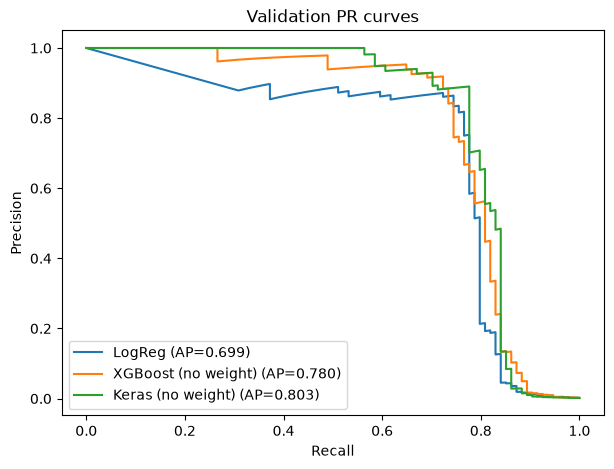

In [8]:
def train_keras(seed=42, mode="none", epochs=200):
    tf.keras.utils.set_random_seed(seed)
    neg, pos = np.bincount(y_train)
    total = neg + pos
    cw = {"none": None,
          "sqrt": {0: 1.0, 1: float(np.sqrt(neg / pos))},
          "balanced": {0: total / (2 * neg), 1: total / (2 * pos)}}[mode]
    model = build_keras(X_train.shape[1], neg, pos,
                        metrics=[keras.metrics.AUC(name="pr_auc", curve="PR")])
    es = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max",
                                       patience=15, restore_best_weights=True)
    hist = model.fit(X_train.values, y_train.values,
                     validation_data=(X_val.values, y_val.values),
                     epochs=epochs, batch_size=2048, class_weight=cw,
                     callbacks=[es], verbose=0)
    best_epoch = int(np.argmax(hist.history["val_pr_auc"])) + 1
    p = model.predict(X_val.values, batch_size=4096, verbose=0).ravel()
    return model, p, best_epoch

val_preds = {}
for mode in ["balanced", "sqrt", "none"]:
    scores, best_epochs = [], []
    for seed in range(1, 6):
        _, p, be = train_keras(seed, mode)
        scores.append(average_precision_score(y_val, p))
        best_epochs.append(be)
        if seed == 1:
            val_preds[mode] = p
    print(f"{mode:9s} mean={np.mean(scores):.3f}  std={np.std(scores):.3f}  best_epochs={best_epochs}")
# expect about 0.708 / 0.708 / 0.785

plt.figure(figsize=(7, 5))
for name, p in [("LogReg", lr.predict_proba(X_val)[:, 1]),
                ("XGBoost (no weight)", xgb_models["no weight"].predict_proba(X_val)[:, 1]),
                ("Keras (no weight)", val_preds["none"])]:
    prec, rec, _ = precision_recall_curve(y_val, p)
    plt.plot(rec, prec, label=f"{name} (AP={average_precision_score(y_val, p):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("Validation PR curves")
plt.savefig("../figures/pr_curves_validation.png", dpi=150)
plt.show()